<center><h1>Blombach_George_HW2</h1>
    George Blombach<br>
    USC ID: 2416096199<br>
    Github: gblombach<br>
    <font size=\"4\">Combined Cycle Power Plant</font></center>

## 1. Combined Cycle Power Plant Data Set

The dataset contains data points collected from a Combined Cycle Power Plant over 6 years (2006-2011), when the power plant was set to work with full load. Features consist of hourly average ambient variables Temperature (T), Ambient Pressure (AP), Relative Humidity (RH) and Exhaust Vacuum (V) to predict the net hourly electrical energy output (EP) of the plant.

### (a) Download Data

Package imports

In [1]:
#pip install pandas numpy openpyxl seaborn matplotlib statsmodels
import warnings
import pandas as pd
import numpy as np
import openpyxl
import seaborn as sb
from scipy.stats import linregress
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import statsmodels.api as sm

from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler, StandardScaler
from sklearn.metrics import mean_squared_error, pairwise
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor


Get the Cycle Power Plant Data Set

There are five sheets in the data. All of them are shuffled versions of the same dataset. **Work with Sheet 1**.

In [2]:
df = pd.read_excel('data/Folds5x2_pp.xlsx',sheet_name='Sheet1')
df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


### (b) Exploring the data

#### i. rows and columns

How many rows are in this data set? How many columns? What do the rows
and columns represent?

In [3]:
rows, columns = df.shape
print('There are', rows,'rows and', columns,'columns.')

There are 9568 rows and 5 columns.


The rows represent hourly increments, and the columns represent average measurements of various environmental conditions: Ambient Temperature (AT), Exhaust Vacuum (V), Ambient Pressure (AP), Relative Humidity (RH), and a prediction of the net hourly electrical energy output (PE).

#### ii. pairwise scatterplots of all the variables

Make pairwise scatterplots of all the variables in the data set including the
predictors (independent variables) with the dependent variable. Describe your 
findings.

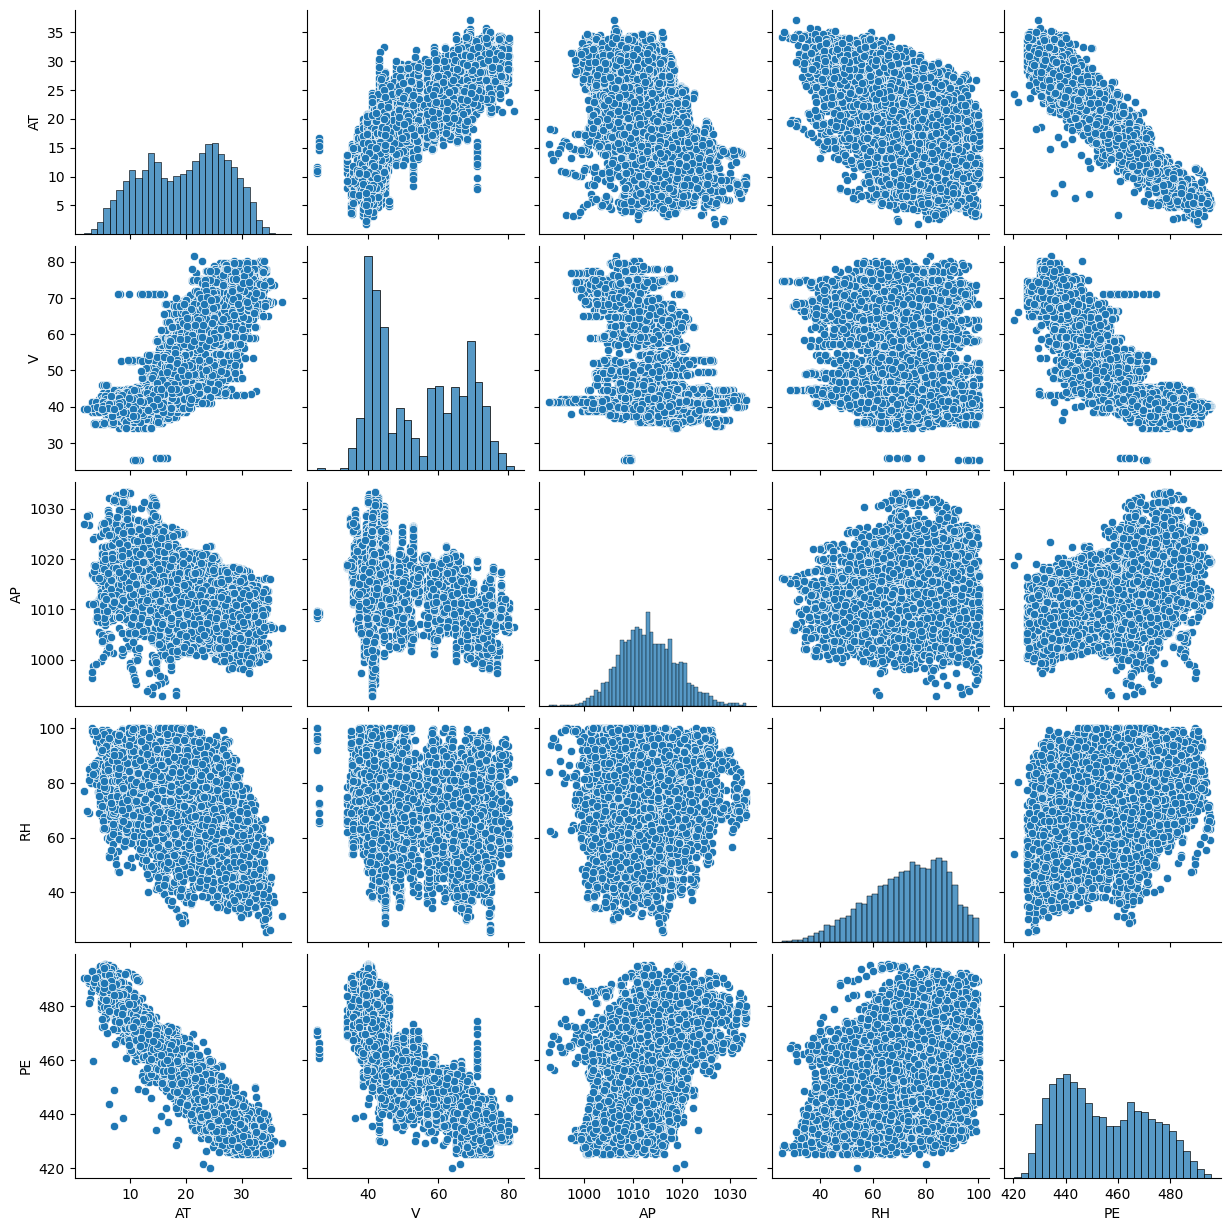

In [4]:
sb.pairplot(df)

The initial impression of the scatterplots indicate there is a negative correlation between both Ambient Tempurature (T) and Exhaust Vacuum (V) to the electrical energy output (PE). However, the correlation between either Ambient Pressure (AP) or Relative Humidity (RH) and the electrical energy output (PE) levels are less obvious as the points in the scatter plots are more broadly distributed.

#### iii. mean, the median, range, first and third quartiles, and interquartile ranges

What are the mean, the median, range,first and third quartiles, and interquartile ranges of each
of the variables in the dataset? Summarize them in a table.

In [5]:
#...but this is easier!
summary = df.describe()
this_range = df.max() - df.min()
iqr = df.quantile(0.75) - df.quantile(0.25)
summary.loc['range'] = this_range
summary.loc['IQR'] = iqr
summary.round(2)

,AT,V,AP,RH,PE
count,9568.00,9568.00,9568.00,9568.00,9568.00
mean,19.65,54.31,1013.26,73.31,454.37
std,7.45,12.71,5.94,14.60,17.07
min,1.81,25.36,992.89,25.56,420.26
25%,13.51,41.74,1009.10,63.33,439.75
50%,20.34,52.08,1012.94,74.97,451.55
75%,25.72,66.54,1017.26,84.83,468.43
max,37.11,81.56,1033.30,100.16,495.76
range,35.30,56.20,40.41,74.60,75.50
IQR,12.21,24.80,8.16,21.50,28.68


### (c) Simple Linear Regression

For each predictor, fit a simple linear regression model to predict the response.
Describe your results. In which of the models is there a statistically significant
association between the predictor and the response? Create some plots to back
up your assertions. Are there any outliers that you would like to remove from
your data for each of these regression tasks?


     #####  Simple Linear Regression Summary for AT and PE :  #####

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.899
Model:                            OLS   Adj. R-squared:                  0.899
Method:                 Least Squares   F-statistic:                 8.510e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        20:24:02   Log-Likelihood:                -29756.
No. Observations:                9568   AIC:                         5.952e+04
Df Residuals:                    9566   BIC:                         5.953e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------

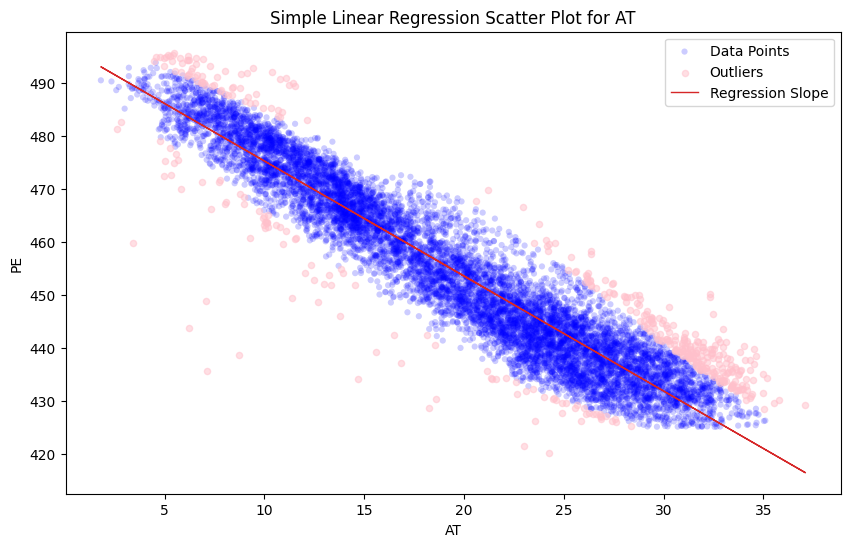


     #####  Simple Linear Regression Summary for V and PE :  #####

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.757
Model:                            OLS   Adj. R-squared:                  0.756
Method:                 Least Squares   F-statistic:                 2.972e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        20:24:02   Log-Likelihood:                -33963.
No. Observations:                9568   AIC:                         6.793e+04
Df Residuals:                    9566   BIC:                         6.794e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------

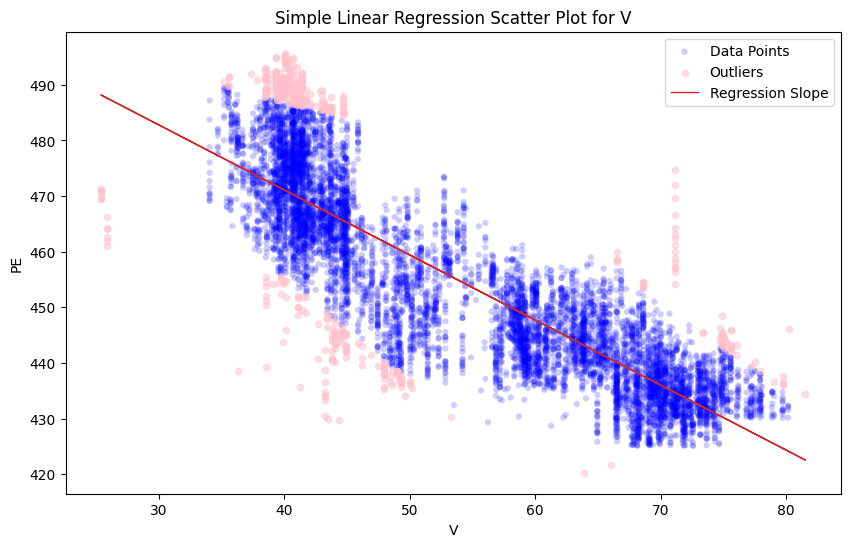


     #####  Simple Linear Regression Summary for AP and PE :  #####

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.269
Model:                            OLS   Adj. R-squared:                  0.269
Method:                 Least Squares   F-statistic:                     3516.
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        20:24:03   Log-Likelihood:                -39224.
No. Observations:                9568   AIC:                         7.845e+04
Df Residuals:                    9566   BIC:                         7.847e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------

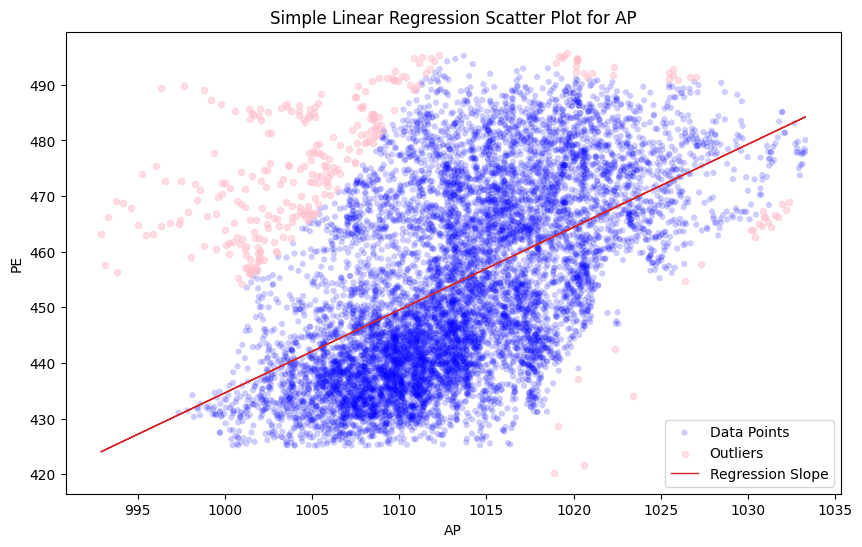


     #####  Simple Linear Regression Summary for RH and PE :  #####

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.152
Model:                            OLS   Adj. R-squared:                  0.152
Method:                 Least Squares   F-statistic:                     1714.
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        20:24:03   Log-Likelihood:                -39933.
No. Observations:                9568   AIC:                         7.987e+04
Df Residuals:                    9566   BIC:                         7.988e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------

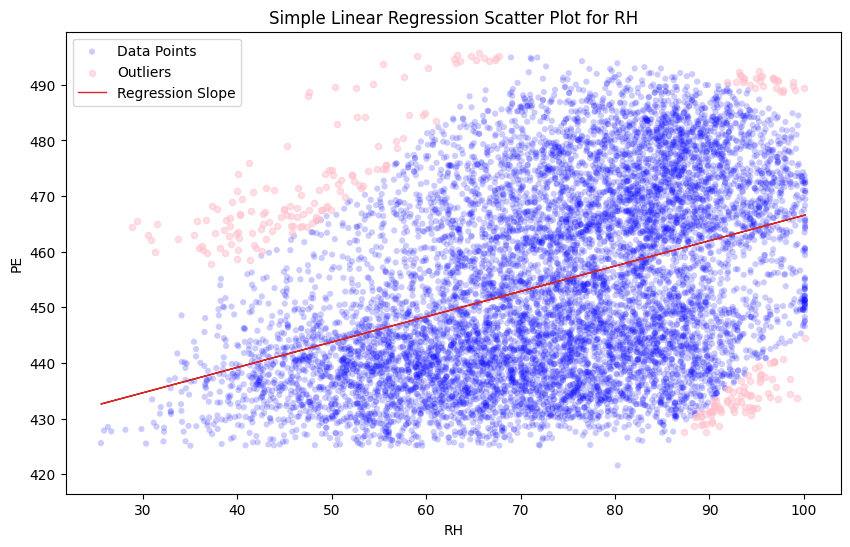

In [6]:
#setup for later
test_errors = dict()

#define target response variable
response = 'PE'

# data for later
linear_coefficients = []

#the rest are predictors
predictors = [col for col in df.columns if col != response]

results =[]

for predictor in predictors:
    
    # Get X and Y
    X = df[[predictor]]
    y = df[response]
    
    # constants
    x_constant = sm.add_constant(X)
    
    # Fit regression
    model = sm.OLS(y, x_constant).fit()

    # predictors
    y_prediction = model.predict(x_constant)

    # get coefficients for later
    linear_coefficients.append(model.params.iloc[1])
    
    # print section header
    print(f"\n     #####  Simple Linear Regression Summary for {predictor} and {response} :  #####\n")

    # print OLS Regression results
    print(model.summary())

    # get outliers using Cooks Distance
    cooks = model.get_influence().cooks_distance
    outliers  = np.where(cooks[0] > 4/len(df))
    
    # define scatterplot charts
    fig, axes = plt.subplots(figsize=(10, 6))

    # predictors
    x_constant = sm.add_constant(X)
    y_pred = model.predict(x_constant)

    # plot
    with plt.style.context('classic'):
        #remove outliers from model results and plot
        axes.scatter(np.delete(X, outliers), np.delete(y, outliers), alpha=0.2, label="Data Points")

        #add outliers to the plot and color pink
        axes.scatter(X.to_numpy()[outliers], y.to_numpy()[outliers], alpha=0.5, color='pink', label="Outliers")
        
        #add slope
        axes.plot(X, y_pred, "tab:red", label="Regression Slope")
    axes.set_title(f"Simple Linear Regression Scatter Plot for {predictor}")
    axes.set_xlabel(f'{predictor}')
    axes.set_ylabel(f'{response}')
    axes.legend()
    plt.show()
    

#### Comments
The p-values for all of the predictors are less than 0.05, incidating that there is statistical significance between the predictors and the response. Each chart reveals 

Yes, I used Cooks Distance to identify outliers in each of the the charts, which have been marked in pink. Although a Piazza post insiciated that they could be removed, I chose to include separate them logically in the code and visually on the graphs in case they needed to be removed.

### (d) Multiple Regression

Fit a multiple regression model to predict the response using all of the predictors. Describe your results. For which predictors can we reject the null hypothesis H0 : Bj = 0?

In [7]:
# Response variable
y = df[response]

# Get all predictors together
x = df.drop(columns=[response])

# Add intercept
x = sm.add_constant(x)

# Fit multiple regression model
model = sm.OLS(y, x).fit()

# save coefficients for later
multiple_coefficients = model.params[1:5]

# Display results
# print section header
print(f"\n     #####  Multiple Variable Regression Fit Summary for All Variables. #####\n")
print(model.summary())



     #####  Multiple Variable Regression Fit Summary for All Variables. #####

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        20:24:03   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------

#### Comments
We can reject the null hypothesis for all predictors in this scenario as the p-values are less than .05.


### (e) 1c Compare to 1d

How do your results from 1c compare to your results from 1d? Create a plot displaying the univariate regression coefficients from 1c on the x-axis, and the multiple regression coefficients from 1d on the y-axis. That is, each predictor is displayed as a single point in the plot. Its coefficient in a simple linear regression model is shown on the x-axis, and its coefficient estimate in the multiple linear regression model is shown on the y-axis.

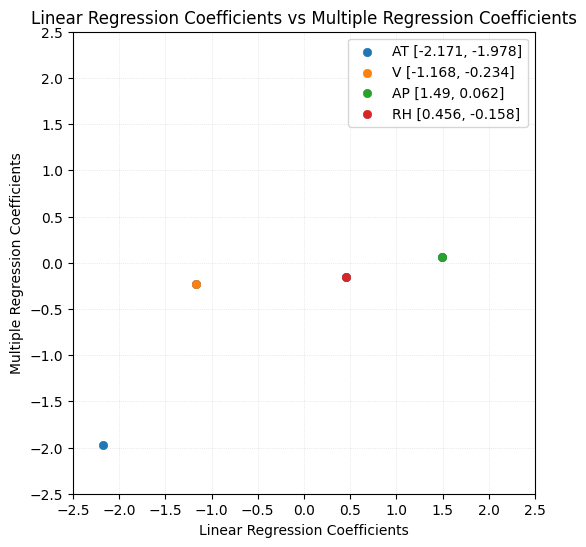

In [8]:
#turn off warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# prepare coefficients
linear_regression_coefficients = np.asarray(linear_coefficients).round(3)
multiple_regression_coefficients = multiple_coefficients.round(3)

fig, axes = plt.subplots(figsize=(6, 6))
plt.xlabel("Linear Regression Coefficients")
plt.ylabel("Multiple Regression Coefficients")
plt.xlim(-2.5, 2.5)
plt.ylim(-2.5, 2.5)
plt.gca().set_aspect('equal', adjustable='box')

with plt.style.context('fivethirtyeight'):
    axes.scatter(linear_regression_coefficients, multiple_regression_coefficients, label=f"AT [{linear_regression_coefficients[0]}, {multiple_regression_coefficients[0]}]")
    axes.scatter(linear_regression_coefficients[1], multiple_regression_coefficients[1], label=f"V [{linear_regression_coefficients[1]}, {multiple_regression_coefficients[1]}]")
    axes.scatter(linear_regression_coefficients[2], multiple_regression_coefficients[2], label=f"AP [{linear_regression_coefficients[2]}, {multiple_regression_coefficients[2]}]")
    axes.scatter(linear_regression_coefficients[3], multiple_regression_coefficients[3], label=f"RH [{linear_regression_coefficients[3]}, {multiple_regression_coefficients[3]}]")

#set title
axes.set_title(f"Linear Regression Coefficients vs Multiple Regression Coefficients")
#set increments
axes.xaxis.set_major_locator(ticker.MultipleLocator(0.5))
axes.yaxis.set_major_locator(ticker.MultipleLocator(0.5))
# add transparent gridlines 
axes.grid(True, linestyle=":", linewidth=0.5, alpha=0.3, c="gray")
axes.legend()
plt.show()


#### Comments
The coefficient values for the Ambient Tempurature (AT) predictor are similar for both linear and multiple regression models. 

However, the coefficient values for the other predictors, (V), (AP) and (RH), vary substanitally between the models. This indicates that these predictors are likely affected by the other predictors somehow.


### (f) Nonlinear Association

Is there evidence of nonlinear association between any of the predictors and the response? To answer this question, for each predictor X, fit a model of the form: Y = B0 + B1 X^2 + B3X^3 + E

https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html

In [9]:
#iterate through predictors
for predictor in predictors:

    #print(predictors)
    #define 3 polynomial features
    pf = PolynomialFeatures(degree=3, include_bias=False)
       
    # Get X 
    x = df[[predictor]]
    y = df[response]
    
    #scale to fix warning on large conditions numbers
    # Standardize predictor
    #scaler = StandardScaler()
    #x_scaled = scaler.fit_transform(x)
           
    #include PolyNomial Features
    x_pf = pf.fit_transform(x)

     #add intercept
    x_pf_sm = sm.add_constant(x_pf)

        
    #fit OLS 
    pf_model = sm.OLS(y,x_pf_sm)
    results = pf_model.fit()
   
    # print section header
    print(f"\n     #####  Nonlinear Regression Summary for {predictor} and {response} :  #####\n")
    #display pf_model summary chart
    print(results.summary())
    


     #####  Nonlinear Regression Summary for AT and PE :  #####

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.912
Model:                            OLS   Adj. R-squared:                  0.912
Method:                 Least Squares   F-statistic:                 3.299e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        20:24:03   Log-Likelihood:                -29101.
No. Observations:                9568   AIC:                         5.821e+04
Df Residuals:                    9564   BIC:                         5.824e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

C:\Users\gblom\AppData\Local\Temp\ipykernel_48748\2986144405.py:26: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  results = pf_model.fit()


#### Comments

##### AT & PE
Since all p-values are zero, the null hypothesis can be rejected becuase there is some evidence of some nonlinear association between AT & PE.

##### V & PE
Since all p-values are not zero, the null hypothesis can't be rejected and there appears to be no significant evidence of nonlinear association between V & PE.

##### AP &PR
Since all p-values are zero, the null hypothesis can be rejected because there is some evidence of some nonlinear association between AT & PE.

##### RH & PE
Since all p-values are zero, the null hypothesis can be rejected and there is evidence of some nonlinear association between RH & PE.


### (g) Interactions of Predictors

Is there evidence of association of interactions of predictors with the response? To answer this question, run a full linear regression model with all pairwise interaction terms and state whether any interaction terms are statistically significant.

In [10]:
#define polynomial feature interaction only true
pf = PolynomialFeatures(interaction_only=True)

# use all predictors together
x = df.drop(columns=[response])
y = df[response]

#transform interactions
x_pf_io = pf.fit_transform(x)

#fit OLS model
pf_io_model = sm.OLS(y, x_pf_io)
results = pf_io_model.fit()

#display variable mapping and results
print(results.summary())

print("\n##### Mapping of Combined Variables: #####\n")
feature_names = pf.get_feature_names_out()
for i, feature in enumerate(feature_names[1:]):
    print(f'x{i+1}', "=", feature)


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                 1.405e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        20:24:03   Log-Likelihood:                -27548.
No. Observations:                9568   AIC:                         5.512e+04
Df Residuals:                    9557   BIC:                         5.520e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        685.7825     78.640      8.721      0.0

#### Comments
Yes, there is evidence of association of some of the interactions of predictors with the response. Specifically, x5 = (AT V), x7 = (AT RH), x8 = (V AP), and x10 = (AP RH) have p-values less than 0.05, and therefore they are statistically significant.
    

### (h) Improvement

Can you improve your model using possible interaction terms or nonlinear associations between the predictors and response? 
Train the regression model on a randomly selected 70% subset of the data with all predictors. Also, run a regression model 
involving all possible interaction terms and quadratic nonlinearities, and remove insignificant variables using p-values 
(be careful about interaction terms). Test both models on the remaining points and report your train and test MSEs.

In [20]:

# use all predictors together
x = df.drop(columns=[response])
y = df[response]

#print(x)
#split the data:70% train and 30% test, randomly (random_state value does not matter)
x_train, x_test, y_train, y_test = train_test_split(x,y,train_size=0.7, random_state=333)

#regression WITHOUT interaction terms and quadratic nonlinearities
x_train_without_sm = sm.add_constant(x_train)
x_test_without_sm = sm.add_constant(x_test)

# fit OLS model
model_without = sm.OLS(y_train,x_train_without_sm)
model_without_results = model_without.fit()

#predict
train_without_predict = model_without_results.predict(x_train_without_sm)
test_without_predict = model_without_results.predict(x_test_without_sm)

#calc mse using sklearn
train_without_mse = mean_squared_error(y_train, train_without_predict)
test_without_mse = mean_squared_error(y_test, test_without_predict)
test_errors['Linear Regression Without Interaction'] = test_without_mse

print(model_without_results.summary())

#regression WITH interaction terms and quadratic (x^2) nonlinearities
pf = PolynomialFeatures(degree=2, include_bias=False)
x_train_with_transform = pf.fit_transform(x_train)
x_test_with_transform = pf.transform(x_test)

feature_names = pf.get_feature_names_out(predictors)

x_train_with_transform = pd.DataFrame(x_train_with_transform, columns=feature_names, index=x_train.index)
x_test_with_transform = pd.DataFrame(x_test_with_transform, columns=feature_names, index=x_test.index)

#intercepts
x_train_with_transform = sm.add_constant(x_train_with_transform)
x_test_with_transform = sm.add_constant(x_test_with_transform)

#fit OLS model
model_with = sm.OLS(y_train, x_train_with_transform)
model_with_results = model_with.fit()

print(model_with_results.summary())

# Check how features are combined
display(pf.get_feature_names_out())

#current features: array(['AT', 'V', 'AP', 'RH', 'AT^2', 'AT V', 'AT AP', 'AT RH', 'V^2','V AP', 'V RH', 'AP^2', 'AP RH', 'RH^2'], dtype=object)
#retain these:
features_retained = ['AT', 'V','RH', 'AT^2', 'AT V','AT RH','AP^2', 'AP RH', 'RH^2']

x_train_with_retained = x_train_with_transform[features_retained]
x_test_with_retained = x_test_with_transform[features_retained]

#add constant
x_train_with_retained = sm.add_constant(x_train_with_retained)
x_test_with_retained = sm.add_constant(x_test_with_retained)

#fit a new model
model_with_retained = sm.OLS(y_train,x_train_with_retained).fit()

#print this mess!
print(model_with_retained.summary())

#calc errors
y_train_with_retained_prediction = model_with_retained.predict(x_train_with_retained)
y_test_with_retained_prediction = model_with_retained.predict(x_test_with_retained)

train_with_mse = mean_squared_error(y_train,y_train_with_retained_prediction)
test_with_mse = mean_squared_error(y_test,y_test_with_retained_prediction)

test_errors['Linear Regression With Interaction'] = test_with_mse

#print results
print("Model WITHOUT Interaction:")
print("\tTrain MSE = ", round(train_without_mse, 3))
print("\tTest MSE = ", round(test_without_mse, 3))
print("\nModel WITH Interaction:")
print("\tTrain MSE = ", round(train_with_mse, 3))
print("\tTest MSE = ", round(test_with_mse, 3))



                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 2.193e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:40:29   Log-Likelihood:                -19644.
No. Observations:                6697   AIC:                         3.930e+04
Df Residuals:                    6692   BIC:                         3.933e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        442.6216     11.674     37.916      0.0

array(['AT', 'V', 'AP', 'RH', 'AT^2', 'AT V', 'AT AP', 'AT RH', 'V^2',
       'V AP', 'V RH', 'AP^2', 'AP RH', 'RH^2'], dtype=object)

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.937
Model:                            OLS   Adj. R-squared:                  0.937
Method:                 Least Squares   F-statistic:                 1.108e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:40:29   Log-Likelihood:                -19241.
No. Observations:                6697   AIC:                         3.850e+04
Df Residuals:                    6687   BIC:                         3.857e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        230.5132     30.464      7.567      0.0

#### Comments
Features removed because p-value > .05: x7 = AT*AP, x9 = V^2, x10 = V*AP, x11 = V*RH

Results show that the model has been improved with the addition of the quadratic terms and interactions.


### (i) KNN

KNN Regression:
i. Perform k-nearest neighbor regression for this dataset using both normalized and raw features. Find the value of 
k in [1, 2, ... , 100} that gives you the best fit. Plot the train and test errors in terms of 1/k.


##### Raw Features Results #####

Training MSE:  0.0
Training Best K:  1
Testing MSE:  15.428
Testing Best K:  4


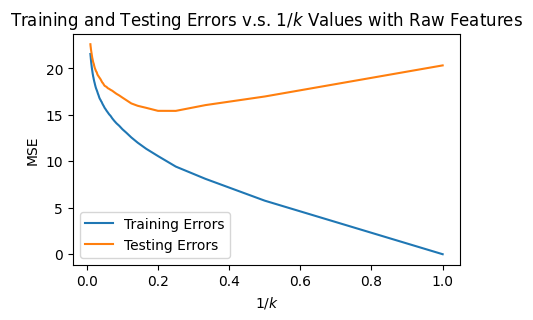


##### Normalized Features Results #####

Training MSE:  0.0
Training Best K:  1
Testing MSE:  14.003
Testing Best K:  4


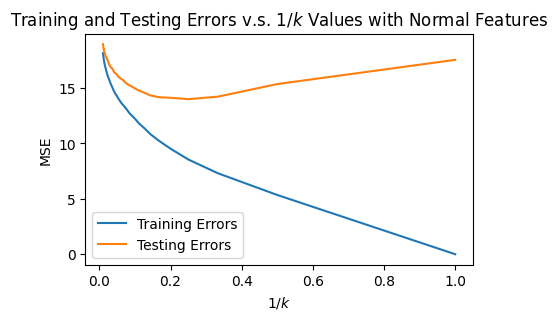

In [12]:
#init
k_values = [i for i in range(1, 101)]
k_inverse = [1/j for j in k_values]

x = df[predictors]
y = df[response]

#split test and train data
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.30,
    random_state=333
)

train_raw_mse=[]
test_raw_mse=[]
train_normal_mse=[]
test_normal_mse=[]


#normalize data
scaler = MinMaxScaler()
model_scaler = scaler.fit(x_train)

# Normalize training and testing data
x_train_normal = model_scaler.transform(x_train)
x_test_normal = model_scaler.transform(x_test)

#iterate k_values
for k in k_values:

    # first process raw data...
    knn = KNeighborsRegressor(n_neighbors = k)
    knn.fit(x_train, y_train)
    
    # predict
    train_raw_prediction = knn.predict(x_train)
    test_raw_prediction = knn.predict(x_test)
    
    # Calc MSE
    train_raw_mse.append(mean_squared_error(y_train, train_raw_prediction))
    test_raw_mse.append(mean_squared_error(y_test, test_raw_prediction))

       
    # ...then process normalized data
    knn_normal = KNeighborsRegressor(n_neighbors = k)
    knn_normal.fit(x_train_normal, y_train)

    # predict
    train_normal_prediction = knn_normal.predict(x_train_normal)
    test_normal_prediction = knn_normal.predict(x_test_normal)

    #calc MSE
    train_normal_mse.append(mean_squared_error(y_train, train_normal_prediction))
    test_normal_mse.append(mean_squared_error(y_test, test_normal_prediction))

    
#raw feature results
print("\n##### Raw Features Results #####\n")
print("Training MSE: ", round(min(train_raw_mse),3))
print("Training Best K: ", k_values[np.argmin(train_raw_mse)])
print("Testing MSE: ", round(min(test_raw_mse),3))
print("Testing Best K: ", k_values[np.argmin(test_raw_mse)])

test_errors['KNN Regression With Raw Features'] = round(min(test_raw_mse),3)

# Plot raw train and test errors in terms of 1/k
plt.figure(figsize=(5, 3))
plt.plot(k_inverse, train_raw_mse, label='Training Errors')
plt.plot(k_inverse, test_raw_mse, label='Testing Errors')
plt.title('Training and Testing Errors v.s. $1/k$ Values with Raw Features')
plt.xlabel('$1/k$')
plt.ylabel('MSE')
plt.legend(loc="lower left")
plt.show()


#normalized feature results
print("\n##### Normalized Features Results #####\n")
print("Training MSE: ", round(min(train_normal_mse),3))
print("Training Best K: ", k_values[np.argmin(train_normal_mse)])
print("Testing MSE: ", round(min(test_normal_mse),3))
print("Testing Best K: ", k_values[np.argmin(test_normal_mse)])

test_errors['KNN Regression With Normalized Features'] = round(min(test_normal_mse),3)

# Plot raw train and test errors in terms of 1/k
plt.figure(figsize=(5, 3))
plt.plot(k_inverse, train_normal_mse, label='Training Errors')
plt.plot(k_inverse, test_normal_mse, label='Testing Errors')
plt.title('Training and Testing Errors v.s. $1/k$ Values with Normal Features')
plt.xlabel('$1/k$')
plt.ylabel('MSE')
plt.legend(loc="lower left")
plt.show()

### (j ) Compare KNN and Linear

Compare the results of KNN Regression with the linear regression model that has the smallest test error and provide your analysis.

In [21]:
# display model comparison error table 
error_analysis = pd.DataFrame(test_errors.items(), columns= ['Model Name', 'Test Errors'])
display(error_analysis)

,Model Name,Test Errors
0,Linear Regression Without Interaction,21.013733
1,Linear Regression With Interaction,18.572142
2,KNN Regression With Raw Features,15.428000
3,KNN Regression With Normalized Features,14.003000


#### Comments
Observing the table comparison of models used against this dataset, both KNN models performed better and with fewer errors than the two linear regressiton models. Also, the smallest test error from all models was produced by the KNN Regression with normizaliation features. 

## 2. ISLR: 2.4.1

For each of parts (a) through (d), indicate whether we would generally expect the performance of a flexible statistical learning method to be better or worse than an inflexible method. Justify your answer.

(a) The sample size n is extremely large, and the number of predictors p is small.

(b) The number of predictors p is extremely large, and the number of observations n is small.

(c) The relationship between the predictors and response is highly non-linear.

(d) The variance of the error terms, i.e. σ2 = Var(ϵ), is extremely high.

### (a) The sample size n is extremely large, and the number of predictors p is small.

In a scenario where the sample size is very large and the number of predictors is relatively small, we would expect a more flexible statistical learning method to **perform better**. The risk of overfitting due to the complexity of predictor-response relationships is reduced by providing plenty of data for sampling. Also, because P is small with only a few predictors, flexible methods can estimate better due to low dimensionality.

### (b) The number of predictors p is extremely large, and the number of observations n is small.

In a scenario where the number of predictors is very large and the number of observations is small, we would expect a the flexible statistical learning method to **perform worse**.  The risk of overfitting due to the complexity of predictor-response relationships is increased when there is not enough data from fewer obeservations. Also, because P is very large with many predictors, flexible methods can suffer due to high dimensionality.

### (c) The relationship between the predictors and response is highly non-linear.

In a scenario where the relationship between predictors and a response is highly nonlinear, we would expect the flexible statistical learning method to **perform better**. This is because inflexible methods like simple linear regression might not be able to completely reveal complex relationships between predictors and a response due to underfitting of the data. Also, flexible methods can more easily adapt to predictor interactions and nonlinear asssociations.

### (d) The variance of the error terms, i.e. $σ^2$ = Var(ε), is extremely high.

In a scenario where the variance of the error terms is very high, we would expect the flexible statistical learning model to **perform worse**. Flexible models are more likely to chase random noise rather than the actual predictors, and lead to overfitting the data. This can also lead to higher testing errors.

## 3. ISLR: 2.4.7

The table below provides a training data set containing six observations, three predictors, and one qualitative response variable.

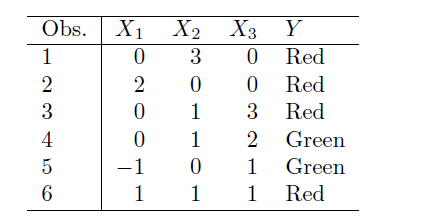
   
Suppose we wish to use this data set to make a prediction for Y when
X1 = X2 = X3 = 0 using K-nearest neighbors.

(a) Compute the Euclidean distance between each observation and the test point, X1 = X2 = X3 = 0.

(b) What is our prediction with K = 1? Why?

(c) What is our prediction with K = 3? Why?

(d) If the Bayes decision boundary in this problem is highly nonlinear, then would we expect the best value for K to be large or small? Why?

### (a) Compute the Euclidean distance between each observation and the test point, X1 = X2 = X3 = 0.

The formula for caculating the euclidean distance from the test point (0,0,0) is 
$$
d = \sqrt{(x_1-0)^2 + (x_2-0)^2 + (x_3-0)^2}
$$


In [ ]:
#add table data to dataframe
df_247 = pd.DataFrame({
    'x1': [0, 2, 0, 0, -1, 1],
    'x2': [3, 0, 1, 1, 0, 1],
    'x3': [0, 0, 3, 2, 1, 1],
    'Class':['Red','Red','Red','Green','Green','Red']
})
test_point = [[0,0,0]]

    #caluclate Euclidean distance 
df_247['Euclidean Distance'] = np.sqrt((df_247['x1'] - 0)**2 + (df_247['x2'] - 0)**2 + (df_247['x3'] - 0) **2)
#fix ordinal
df_247.index = range(1, len(df_247) +1)
#display
display(df_247)

### (b) What is our prediction with K = 1? Why?

Our prediction is <span style='color:green'>GREEN</span>.  When K=1, we use the nearest observation to the test point (0,0,0), which is the point (-1,0,1) at #5, with the lowest distance of $\sqrt{2}$. 

### (c) What is our prediction with K = 3? Why?

Our prediction is <span style='color:red'>RED</span>. When k=3, we look at the 3 closest points to the test point (0,0,0), which are:

- #5: $\sqrt{2}$ from point (-1,0,1)
- #6: $\sqrt{3}$ from point (1,1,1)
- #3: $\sqrt{4}$ = 2 from point (2,0,0)

The majority class for these data points is <span style='color:red'>RED</span>.

### (d) If the Bayes decision boundary in this problem is highly non-linear, then would we expect the best value for K to be large or small? Why?

We expect the best value for K is small when the Bayes decision boundary is hightly nonlinear. Being highly non-linear means that the boundry between classes will be curvy and change shapes frequently. A small K value is better in this scenario because it allows the classifer to be more flexible to local variations.